# Parkinson's Detection: Dual-Branch CNN (Spiral + Meander)

Pipeline:
1. Load HandPD data, build Spiral/Meander pairs, split by **participant**
2. Antialiased grayscale loading (no colour shortcuts)
3. Small CNN trained from scratch (no transfer learning)
4. 5-fold participant-grouped cross-validation, fold-ensemble
5. Participant-level evaluation + Grad-CAM

## 1. Setup

In [22]:
import os, re, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from tensorflow.keras import layers, Model, regularizers
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
                             balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# ---------------- Config ----------------
SEED = 42
IMG_SIZE = (192, 192)      # try (128,128), (192,192), (256,256) and compare CV AUC
EPOCHS = 40                # train longer so the small CNN can separate both classes
N_FOLDS = 5
BATCH_SIZE = 8             # smaller batch gives more updates per epoch
LR = 3e-4                  # lower learning rate for stable training
FILTERS = [16, 32, 64] if IMG_SIZE[0] <= 128 else [16, 32, 64, 64]

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.22.0-rc0
GPU: []


In [23]:
# Google Colab compatibility: local VS Code skips Drive mounting.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Running locally in VS Code; skipping Google Drive mount.")

Running locally in VS Code; skipping Google Drive mount.


## 2. Dataset paths and extraction

In [24]:
from pathlib import Path

# Resolve the dataset from either the notebook folder or the workspace root.
_here = Path.cwd().resolve()
_dataset_candidates = [
    _here / "NewHandPD Dataset",
    _here.parent / "NewHandPD Dataset",
    _here,
    _here.parent,
]
DATASET_DIR = next(
    (path for path in _dataset_candidates if (path / "csv").is_dir()),
    None,
)
if DATASET_DIR is None:
    raise FileNotFoundError(
        "Could not find the local dataset folder containing csv/NewMeander.csv. "
        f"Checked: {_dataset_candidates}"
    )

ZIP_PATH = DATASET_DIR / "new_handpd_dataset.zip"  # optional; unused locally
MEANDER_CSV = DATASET_DIR / "csv" / "NewMeander.csv"
SPIRAL_CSV = DATASET_DIR / "csv" / "NewSpiral.csv"
EXTRACT_DIR = DATASET_DIR
MODEL_DIR = DATASET_DIR.parent / "models"

assert MEANDER_CSV.exists(), f"CSV not found: {MEANDER_CSV}"
assert SPIRAL_CSV.exists(), f"CSV not found: {SPIRAL_CSV}"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_DIR)
print("Models :", MODEL_DIR)

Dataset: C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\NewHandPD Dataset
Models : C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\models


In [25]:
def find_folder(root, target_name):
    matches = []
    for current_root, dirs, _ in os.walk(root):
        for directory in dirs:
            if directory.lower() == target_name.lower():
                matches.append(os.path.join(current_root, directory))

    if not matches:
        raise FileNotFoundError(f"Folder '{target_name}' was not found inside {root}")
    if len(matches) > 1:
        print(f"Warning: multiple '{target_name}' folders found; using: {matches[-1]}")
    return matches[-1]


FOLDERS = {
    "healthy_meander": find_folder(EXTRACT_DIR, "HealthyMeander"),
    "healthy_spiral": find_folder(EXTRACT_DIR, "HealthySpiral"),
    "patient_meander": find_folder(EXTRACT_DIR, "PatientMeander"),
    "patient_spiral": find_folder(EXTRACT_DIR, "PatientSpiral"),
}

for name, path in FOLDERS.items():
    n = len([f for f in os.listdir(path) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"{name}: {n} images | {path}")

healthy_meander: 140 images | C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\NewHandPD Dataset\HealthyMeander\HealthyMeander
healthy_spiral: 140 images | C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\NewHandPD Dataset\HealthySpiral\HealthySpiral
patient_meander: 124 images | C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\NewHandPD Dataset\PatientMeander\PatientMeander
patient_spiral: 124 images | C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\NewHandPD Dataset\PatientSpiral\PatientSpiral


## 3. Labels and Spiral/Meander pairs

In [26]:
meander_df = pd.read_csv(MEANDER_CSV)
spiral_df = pd.read_csv(SPIRAL_CSV)

print("Meander shape:", meander_df.shape)
print("Spiral shape:", spiral_df.shape)
print("\nMeander class counts:\n", meander_df["CLASS_TYPE"].value_counts())
print("\nSpiral class counts:\n", spiral_df["CLASS_TYPE"].value_counts())

Meander shape: (264, 16)
Spiral shape: (264, 16)

Meander class counts:
 CLASS_TYPE
1    140
2    124
Name: count, dtype: int64

Spiral class counts:
 CLASS_TYPE
1    140
2    124
Name: count, dtype: int64


In [27]:
def add_repetition_number(df, prefix):
    df = df.copy()
    pattern = rf"^{prefix}(\d+)-"
    df["REPETITION"] = (
        df["IMAGE_NAME"].astype(str)
        .str.extract(pattern, flags=re.IGNORECASE)[0]
    )
    if df["REPETITION"].isna().any():
        bad = df.loc[df["REPETITION"].isna(), "IMAGE_NAME"].tolist()
        raise ValueError(f"Could not parse repetition number: {bad[:10]}")
    df["REPETITION"] = df["REPETITION"].astype(int)
    return df


meander_df = add_repetition_number(meander_df, "mea")
spiral_df = add_repetition_number(spiral_df, "sp")

# Same exam must have the same class in both CSV files
label_check = meander_df[["_ID_EXAM", "REPETITION", "CLASS_TYPE"]].merge(
    spiral_df[["_ID_EXAM", "REPETITION", "CLASS_TYPE"]],
    on=["_ID_EXAM", "REPETITION"], how="outer",
    suffixes=("_MEANDER", "_SPIRAL"), indicator=True)

assert (label_check["_merge"] == "both").all(), "Unmatched Meander/Spiral records."
assert (label_check["CLASS_TYPE_MEANDER"] == label_check["CLASS_TYPE_SPIRAL"]).all(), \
    "Class labels differ between the two CSV files."

pairs = meander_df.merge(
    spiral_df, on=["_ID_EXAM", "REPETITION"],
    suffixes=("_MEANDER", "_SPIRAL"), validate="one_to_one")

# CLASS_TYPE: 1 = Healthy, 2 = Parkinson's
pairs["LABEL"] = (pairs["CLASS_TYPE_MEANDER"] == 2).astype(np.int32)
pairs = pairs.rename(columns={
    "IMAGE_NAME_MEANDER": "MEANDER_IMAGE",
    "IMAGE_NAME_SPIRAL": "SPIRAL_IMAGE"})

print("Number of image pairs:", len(pairs))
print("Number of unique participants:", pairs["_ID_EXAM"].nunique())
pairs[["_ID_EXAM", "REPETITION", "MEANDER_IMAGE", "SPIRAL_IMAGE", "LABEL"]].head(10)

Number of image pairs: 264
Number of unique participants: 66


,_ID_EXAM,REPETITION,MEANDER_IMAGE,SPIRAL_IMAGE,LABEL
0,H1,1,mea1-H1.jpg,sp1-H1.jpg,0
1,H2,1,mea1-H2.jpg,sp1-H2.jpg,0
2,H3,1,mea1-H3.jpg,sp1-H3.jpg,0
3,H4,1,mea1-H4.jpg,sp1-H4.jpg,0
4,H5,1,mea1-H5.jpg,sp1-H5.jpg,0
5,H7,1,mea1-H7.jpg,sp1-H7.jpg,0
6,H8,1,mea1-H8.jpg,sp1-H8.jpg,0
7,H9,1,mea1-H9.jpg,sp1-H9.jpg,0
8,H10,1,mea1-H10.jpg,sp1-H10.jpg,0
9,H11,1,mea1-H11.jpg,sp1-H11.jpg,0


In [28]:
IMAGE_ALIASES = {
    # The CSV references mea4-P8.jpg, but the supplied dataset stores it as mea5-P8.jpg.
    "mea4-P8.jpg": "mea5-P8.jpg",
}


def get_image_path(filename, folder):
    filename = IMAGE_ALIASES.get(str(filename), str(filename))
    path = os.path.join(folder, filename)
    if os.path.exists(path):
        return path
    matches = glob.glob(os.path.join(folder, "**", filename), recursive=True)
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Image not found: {filename}\nFolder: {folder}")


def resolve_image_paths(row):
    if row["LABEL"] == 0:
        m_folder, s_folder = FOLDERS["healthy_meander"], FOLDERS["healthy_spiral"]
    else:
        m_folder, s_folder = FOLDERS["patient_meander"], FOLDERS["patient_spiral"]
    return pd.Series({
        "MEANDER_PATH": get_image_path(row["MEANDER_IMAGE"], m_folder),
        "SPIRAL_PATH": get_image_path(row["SPIRAL_IMAGE"], s_folder)})


pairs[["MEANDER_PATH", "SPIRAL_PATH"]] = pairs.apply(resolve_image_paths, axis=1)
print("All image paths resolved successfully!")
pairs[["_ID_EXAM", "MEANDER_PATH", "SPIRAL_PATH", "LABEL"]].head()

All image paths resolved successfully!


,_ID_EXAM,MEANDER_PATH,SPIRAL_PATH,LABEL
0,H1,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,0
1,H2,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,0
2,H3,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,0
3,H4,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,0
4,H5,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,C:\Users\kanis\Desktop\model\handpd_5th_newHan...,0


## 4. Participant-level split

The test set (10 participants) is the same one used in the earlier experiments and is touched only once at the end.
Train + validation (56 participants) are merged into one **development set** for cross-validation.

In [29]:
assert (pairs.groupby("_ID_EXAM")["LABEL"].nunique() == 1).all(), \
    "A participant has inconsistent labels."

subjects = pairs.groupby("_ID_EXAM")["LABEL"].first().reset_index()

train_subj, temp_subj = train_test_split(
    subjects, test_size=0.30, random_state=SEED, stratify=subjects["LABEL"])
val_subj, test_subj = train_test_split(
    temp_subj, test_size=0.50, random_state=SEED, stratify=temp_subj["LABEL"])

dev_ids = set(train_subj["_ID_EXAM"]) | set(val_subj["_ID_EXAM"])
test_ids = set(test_subj["_ID_EXAM"])
assert dev_ids.isdisjoint(test_ids)

dev_df = pairs[pairs["_ID_EXAM"].isin(dev_ids)].reset_index(drop=True)
test_df = pairs[pairs["_ID_EXAM"].isin(test_ids)].reset_index(drop=True)

print(f"Development: {len(dev_ids)} participants, {len(dev_df)} pairs")
print(f"Test       : {len(test_ids)} participants, {len(test_df)} pairs")
print("\nDev labels:\n", dev_df["LABEL"].value_counts())
print("\nTest labels:\n", test_df["LABEL"].value_counts())

Development: 56 participants, 224 pairs
Test       : 10 participants, 40 pairs

Dev labels:
 LABEL
0    116
1    108
Name: count, dtype: int64

Test labels:
 LABEL
0    24
1    16
Name: count, dtype: int64


## 5. Image loading

Grayscale + **antialiased (LANCZOS)** resize, then inverted so the ink is bright and the paper is 0.
Nearest-neighbour resizing (the Keras default) breaks thin pen lines when shrinking 680 px images.

In [30]:
def load_gray_image(path):
    img = Image.open(path).convert("L")
    img = img.resize((IMG_SIZE[1], IMG_SIZE[0]), Image.LANCZOS)
    arr = np.asarray(img, dtype=np.float32) / 255.0
    arr = 1.0 - arr                      # ink = high, paper = 0
    return arr[..., None]                # (H, W, 1)


def create_arrays(df):
    X_spiral = np.stack([load_gray_image(p) for p in df["SPIRAL_PATH"]])
    X_meander = np.stack([load_gray_image(p) for p in df["MEANDER_PATH"]])
    y = df["LABEL"].to_numpy(dtype=np.int32)
    groups = df["_ID_EXAM"].to_numpy()
    return X_spiral, X_meander, y, groups


Xs_dev, Xm_dev, y_dev, g_dev = create_arrays(dev_df)
Xs_test, Xm_test, y_test, g_test = create_arrays(test_df)

print("Dev spiral :", Xs_dev.shape)
print("Dev meander:", Xm_dev.shape)
print("Test spiral:", Xs_test.shape)

Dev spiral : (224, 192, 192, 1)
Dev meander: (224, 192, 192, 1)
Test spiral: (40, 192, 192, 1)


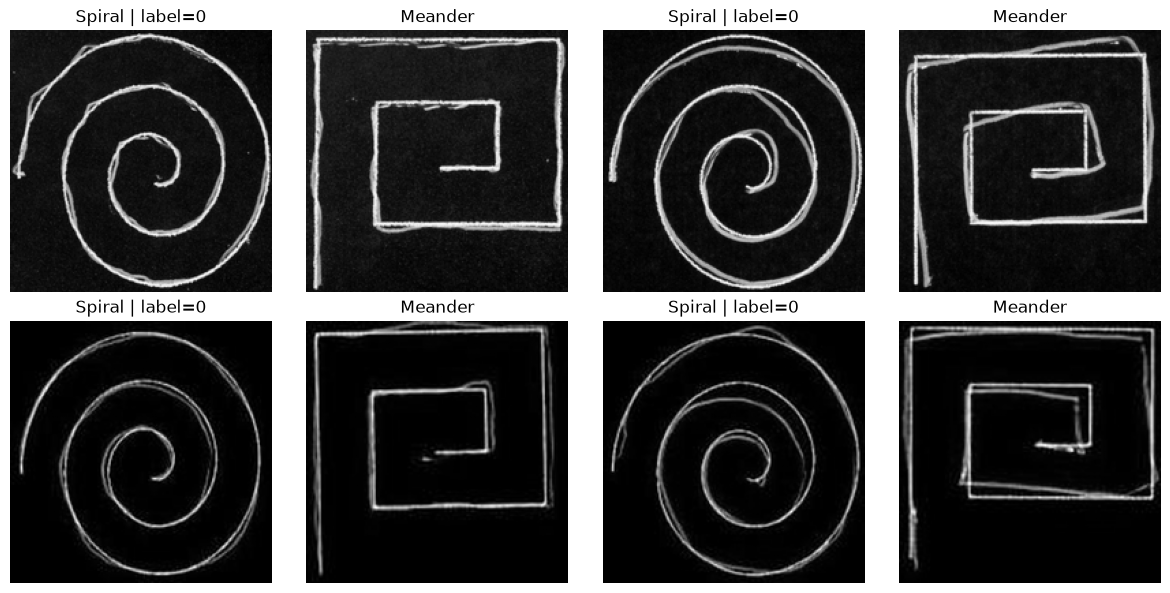

In [31]:
# Quick visual check (spiral | meander)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k, idx in enumerate([0, len(dev_df) // 2]):
    ax[k, 0].imshow(Xs_dev[idx, ..., 0], cmap="gray")
    ax[k, 0].set_title(f"Spiral | label={y_dev[idx]}")
    ax[k, 1].imshow(Xm_dev[idx, ..., 0], cmap="gray")
    ax[k, 1].set_title("Meander")
    ax[k, 2].imshow(Xs_dev[idx + 1, ..., 0], cmap="gray")
    ax[k, 2].set_title(f"Spiral | label={y_dev[idx + 1]}")
    ax[k, 3].imshow(Xm_dev[idx + 1, ..., 0], cmap="gray")
    ax[k, 3].set_title("Meander")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

## 6. Model (trained from scratch)

In [32]:
def build_model(lr=LR):
    l2 = regularizers.l2(1e-4)
    shape = (IMG_SIZE[0], IMG_SIZE[1], 1)

    def branch(inp, prefix):
        # Augmentation: active only during training
        x = layers.RandomRotation(0.04, fill_mode="constant", fill_value=0.0, name=f"{prefix}_rot")(inp)
        x = layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0, name=f"{prefix}_shift")(x)
        x = layers.RandomZoom(0.1, fill_mode="constant", fill_value=0.0, name=f"{prefix}_zoom")(x)

        for i, f in enumerate(FILTERS, start=1):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False,
                              kernel_regularizer=l2, name=f"{prefix}_conv{i}")(x)
            x = layers.BatchNormalization(momentum=0.9, name=f"{prefix}_bn{i}")(x)
            x = layers.Activation("relu", name=f"{prefix}_relu{i}")(x)
            if i < len(FILTERS):
                x = layers.MaxPooling2D(2, name=f"{prefix}_pool{i}")(x)
                x = layers.SpatialDropout2D(0.05, name=f"{prefix}_sdrop{i}")(x)

        x = layers.GlobalAveragePooling2D(name=f"{prefix}_gap")(x)
        x = layers.Dropout(0.25, name=f"{prefix}_dropout")(x)
        return layers.Dense(32, activation="relu", kernel_regularizer=l2,
                            name=f"{prefix}_features")(x)

    spiral_in = layers.Input(shape, name="spiral_input")
    meander_in = layers.Input(shape, name="meander_input")

    fused = layers.Concatenate(name="feature_fusion")([
        branch(spiral_in, "spiral"), branch(meander_in, "meander")])
    x = layers.Dropout(0.25, name="fusion_dropout")(fused)
    out = layers.Dense(1, activation="sigmoid", name="pd_output")(x)

    model = Model([spiral_in, meander_in], out, name="Parkinsons_Dual_CNN")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                 tf.keras.metrics.AUC(name="auc")])
    return model


build_model().summary()

Model: "Parkinsons_Dual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ spiral_input        │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_input       │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_rot          │ (None, 192, 192,  │          0 │ spiral_input[0][… │
│ (RandomRotation)    │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_rot         │ (None, 192, 192,  │          0 │ meander_input[0]… │
│ (RandomRotation)    │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_shift        │ (None, 192, 192,  │          0 │ spiral_rot[0][0]  │
│ (RandomTranslation) │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_shift       │ (None, 192, 192,  │          0 │ meander_rot[0][0] │
│ (RandomTranslation) │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_zoom         │ (None, 192, 192,  │          0 │ spiral_shift[0][… │
│ (RandomZoom)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_zoom        │ (None, 192, 192,  │          0 │ meander_shift[0]… │
│ (RandomZoom)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_conv1        │ (None, 192, 192,  │        144 │ spiral_zoom[0][0] │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_conv1       │ (None, 192, 192,  │        144 │ meander_zoom[0][… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_bn1          │ (None, 192, 192,  │         64 │ spiral_conv1[0][… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_bn1         │ (None, 192, 192,  │         64 │ meander_conv1[0]… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_relu1        │ (None, 192, 192,  │          0 │ spiral_bn1[0][0]  │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_relu1       │ (None, 192, 192,  │          0 │ meander_bn1[0][0] │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_pool1        │ (None, 96, 96,    │          0 │ spiral_relu1[0][… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_pool1       │ (None, 96, 96,    │          0 │ meander_relu1[0]… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spiral_sdrop1       │ (None, 96, 96,    │          0 │ spiral_pool1[0][

 Total params: 125,729 (491.13 KB)

 Trainable params: 125,025 (488.38 KB)

 Non-trainable params: 704 (2.75 KB)

## 7. 5-fold cross-validation (grouped by participant)

* Epochs are fixed, so no model/epoch selection is done on the held-out fold (unbiased estimates).
* `ReduceLROnPlateau` watches the **training** loss only.
* Out-of-fold (OOF) predictions are used later to choose the decision threshold.

In [33]:
def participant_level(prob, groups, y):
    d = pd.DataFrame({"g": groups, "p": prob, "y": y})
    a = d.groupby("g").agg(p=("p", "mean"), y=("y", "first"))
    return a["p"].to_numpy(), a["y"].to_numpy()


skf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_prob = np.zeros(len(y_dev), dtype=np.float32)
fold_models, histories = [], []

for fold, (tr, va) in enumerate(skf.split(Xs_dev, y_dev, g_dev), start=1):
    tf.keras.utils.set_random_seed(SEED + fold)

    cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_dev[tr])
    model = build_model()

    hist = model.fit(
        [Xs_dev[tr], Xm_dev[tr]], y_dev[tr],
        validation_data=([Xs_dev[va], Xm_dev[va]], y_dev[va]),   # for curves only
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        class_weight={0: float(cw[0]), 1: float(cw[1])},
        callbacks=[tf.keras.callbacks.ReduceLROnPlateau(
            monitor="loss", factor=0.5, patience=4, min_lr=1e-6, verbose=2)],
        verbose=2)

    oof_prob[va] = model.predict([Xs_dev[va], Xm_dev[va]], verbose=0).ravel()
    fold_models.append(model)
    histories.append(hist.history)

    p, t = participant_level(oof_prob[va], g_dev[va], y_dev[va])
    print(f"Fold {fold}: train_acc={hist.history['accuracy'][-1]:.3f} | "
          f"pair AUC={roc_auc_score(y_dev[va], oof_prob[va]):.3f} | "
          f"participant acc@0.5={accuracy_score(t, p >= 0.5):.3f} "
          f"({len(t)} participants)")

Epoch 1/40
22/22 - 11s - 496ms/step - accuracy: 0.6420 - auc: 0.7321 - loss: 0.6643 - val_accuracy: 0.5000 - val_auc: 0.6892 - val_loss: 0.7144 - learning_rate: 3.0000e-04
Epoch 2/40
22/22 - 6s - 288ms/step - accuracy: 0.8011 - auc: 0.8662 - loss: 0.5186 - val_accuracy: 0.6667 - val_auc: 0.7214 - val_loss: 0.7157 - learning_rate: 3.0000e-04
Epoch 3/40
22/22 - 7s - 316ms/step - accuracy: 0.8182 - auc: 0.8701 - loss: 0.4785 - val_accuracy: 0.6667 - val_auc: 0.7543 - val_loss: 0.6774 - learning_rate: 3.0000e-04
Epoch 4/40
22/22 - 7s - 299ms/step - accuracy: 0.8125 - auc: 0.8333 - loss: 0.5037 - val_accuracy: 0.6667 - val_auc: 0.7865 - val_loss: 0.6824 - learning_rate: 3.0000e-04
Epoch 5/40
22/22 - 7s - 311ms/step - accuracy: 0.8239 - auc: 0.8404 - loss: 0.4804 - val_accuracy: 0.6667 - val_auc: 0.8090 - val_loss: 0.7070 - learning_rate: 3.0000e-04
Epoch 6/40
22/22 - 10s - 457ms/step - accuracy: 0.8182 - auc: 0.8540 - loss: 0.4678 - val_accuracy: 0.6667 - val_auc: 0.8238 - val_loss: 0.6881 

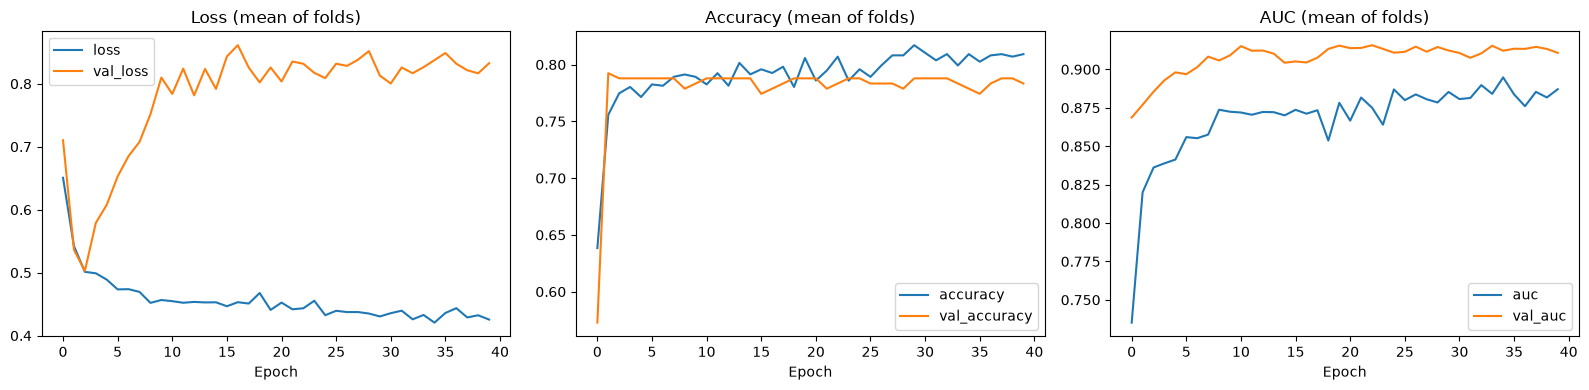

In [34]:
# Average learning curves over the folds
def mean_curve(key):
    return np.mean([h[key] for h in histories], axis=0)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for key in ["loss", "val_loss"]:
    ax[0].plot(mean_curve(key), label=key)
ax[0].set_title("Loss (mean of folds)"); ax[0].legend(); ax[0].set_xlabel("Epoch")

for key in ["accuracy", "val_accuracy"]:
    ax[1].plot(mean_curve(key), label=key)
ax[1].set_title("Accuracy (mean of folds)"); ax[1].legend(); ax[1].set_xlabel("Epoch")

for key in ["auc", "val_auc"]:
    ax[2].plot(mean_curve(key), label=key)
ax[2].set_title("AUC (mean of folds)"); ax[2].legend(); ax[2].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

## 8. Out-of-fold results and decision threshold

In [35]:
p_oof, t_oof = participant_level(oof_prob, g_dev, y_dev)

print("OOF pair-level AUC       :", round(roc_auc_score(y_dev, oof_prob), 4))
print("OOF participant-level AUC:", round(roc_auc_score(t_oof, p_oof), 4))

fpr, tpr, thr = roc_curve(t_oof, p_oof)
best_thr = float(thr[np.argmax(tpr - fpr)])          # Youden's J
print("Chosen threshold (OOF)   :", round(best_thr, 4))

oof_pred = (p_oof >= best_thr).astype(int)
print("OOF participant accuracy :", round(accuracy_score(t_oof, oof_pred), 4))
print("OOF balanced accuracy    :", round(balanced_accuracy_score(t_oof, oof_pred), 4))
print()
print(classification_report(t_oof, oof_pred, target_names=["Healthy", "Parkinson's"], zero_division=0))

OOF pair-level AUC       : 0.8932
OOF participant-level AUC: 0.8953
Chosen threshold (OOF)   : 0.9341
OOF participant accuracy : 0.875
OOF balanced accuracy    : 0.878

              precision    recall  f1-score   support

     Healthy       0.96      0.79      0.87        29
 Parkinson's       0.81      0.96      0.88        27

    accuracy                           0.88        56
   macro avg       0.89      0.88      0.87        56
weighted avg       0.89      0.88      0.87        56



## 9. Final test (ensemble of the 5 fold models)

Reported at **pair level** (each image pair) and **participant level**
(mean probability of the participant's pairs).

In [36]:
test_prob = np.mean(
    [m.predict([Xs_test, Xm_test], verbose=0).ravel() for m in fold_models], axis=0)

# ---- pair level ----
pair_pred = (test_prob >= best_thr).astype(int)
print("=== TEST: pair level ===")
print("Accuracy         :", round(accuracy_score(y_test, pair_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, pair_pred), 4))
print("ROC-AUC          :", round(roc_auc_score(y_test, test_prob), 4))
print(classification_report(y_test, pair_pred, target_names=["Healthy", "Parkinson's"], zero_division=0))

# ---- participant level ----
p_test, t_test = participant_level(test_prob, g_test, y_test)
part_pred = (p_test >= best_thr).astype(int)
print("=== TEST: participant level ===")
print("Accuracy         :", round(accuracy_score(t_test, part_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(t_test, part_pred), 4))
print("ROC-AUC          :", round(roc_auc_score(t_test, p_test), 4))
print(classification_report(t_test, part_pred, target_names=["Healthy", "Parkinson's"], zero_division=0))

=== TEST: pair level ===
Accuracy         : 0.8
Balanced accuracy: 0.8333
ROC-AUC          : 0.7552
              precision    recall  f1-score   support

     Healthy       1.00      0.67      0.80        24
 Parkinson's       0.67      1.00      0.80        16

    accuracy                           0.80        40
   macro avg       0.83      0.83      0.80        40
weighted avg       0.87      0.80      0.80        40

=== TEST: participant level ===
Accuracy         : 0.8
Balanced accuracy: 0.8333
ROC-AUC          : 0.7083
              precision    recall  f1-score   support

     Healthy       1.00      0.67      0.80         6
 Parkinson's       0.67      1.00      0.80         4

    accuracy                           0.80        10
   macro avg       0.83      0.83      0.80        10
weighted avg       0.87      0.80      0.80        10



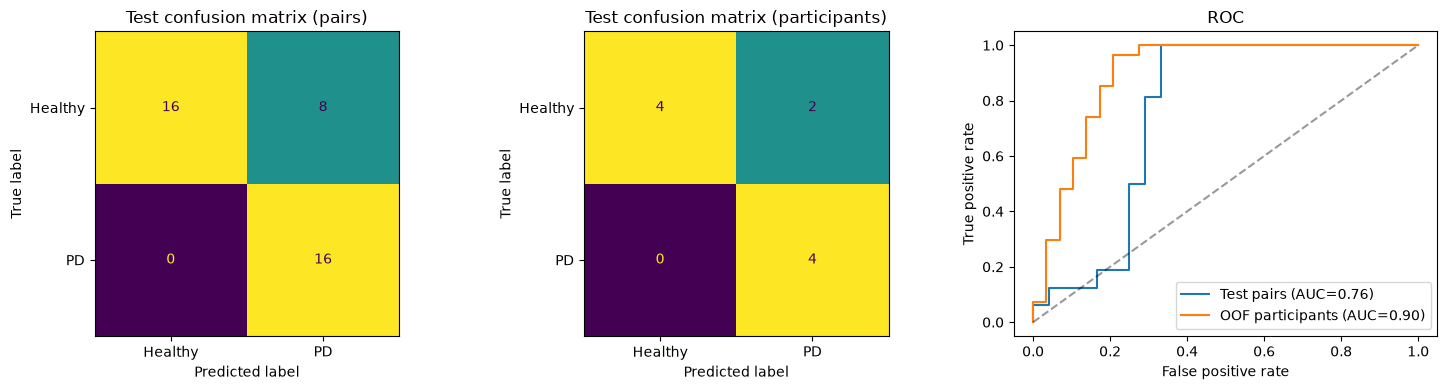

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ConfusionMatrixDisplay(confusion_matrix(y_test, pair_pred),
                       display_labels=["Healthy", "PD"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Test confusion matrix (pairs)")

ConfusionMatrixDisplay(confusion_matrix(t_test, part_pred),
                       display_labels=["Healthy", "PD"]).plot(ax=ax[1], colorbar=False)
ax[1].set_title("Test confusion matrix (participants)")

f1, t1, _ = roc_curve(y_test, test_prob)
f2, t2, _ = roc_curve(t_oof, p_oof)
ax[2].plot(f1, t1, label=f"Test pairs (AUC={roc_auc_score(y_test, test_prob):.2f})")
ax[2].plot(f2, t2, label=f"OOF participants (AUC={roc_auc_score(t_oof, p_oof):.2f})")
ax[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC"); ax[2].legend()
plt.tight_layout()
plt.show()

## 10. Grad-CAM

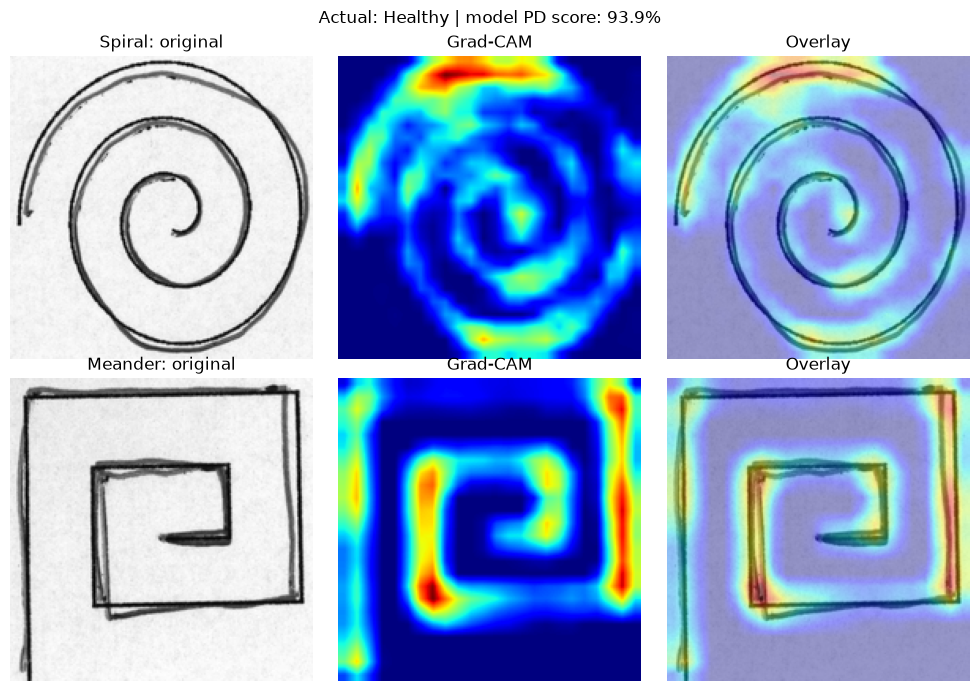

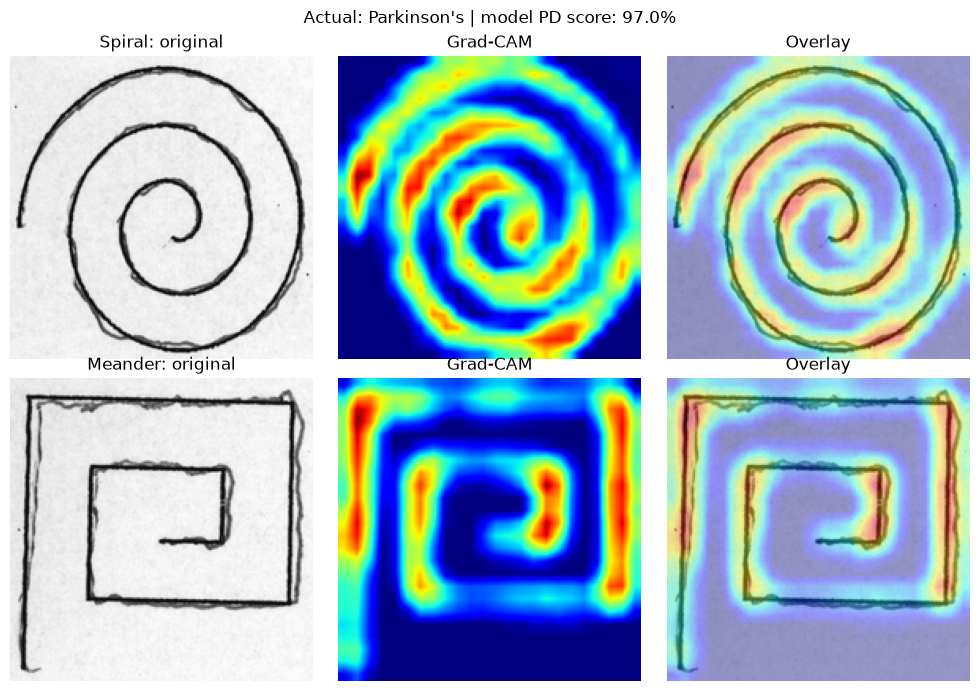

In [38]:
def grad_cam(model, spiral_img, meander_img, branch="spiral"):
    # Heatmap from the last ReLU of the chosen branch
    layer = model.get_layer(f"{branch}_relu{len(FILTERS)}")
    cam_model = Model(model.inputs, [layer.output, model.output])

    s = tf.convert_to_tensor(spiral_img[None], dtype=tf.float32)
    m = tf.convert_to_tensor(meander_img[None], dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_out, pred = cam_model([s, m], training=False)
        score = pred[:, 0]

    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam).numpy()
    cam = cam / (cam.max() + 1e-8)

    cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
    return cam, float(pred.numpy()[0, 0])


def show_gradcam(index, model=None):
    model = model or fold_models[0]
    fig, ax = plt.subplots(2, 3, figsize=(10, 7))
    for r, (name, img) in enumerate([("Spiral", Xs_test[index]), ("Meander", Xm_test[index])]):
        cam, score = grad_cam(model, Xs_test[index], Xm_test[index], name.lower())
        paper = 1.0 - img[..., 0]                    # undo inversion for display
        ax[r, 0].imshow(paper, cmap="gray"); ax[r, 0].set_title(f"{name}: original")
        ax[r, 1].imshow(cam, cmap="jet");    ax[r, 1].set_title("Grad-CAM")
        ax[r, 2].imshow(paper, cmap="gray"); ax[r, 2].imshow(cam, cmap="jet", alpha=0.4)
        ax[r, 2].set_title("Overlay")
    actual = "Parkinson's" if y_test[index] == 1 else "Healthy"
    fig.suptitle(f"Actual: {actual} | model PD score: {score * 100:.1f}%")
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout()
    plt.show()


# One healthy and one Parkinson's example from the test set
show_gradcam(int(np.where(y_test == 0)[0][0]))
show_gradcam(int(np.where(y_test == 1)[0][0]))

## 11. Save models and settings

In [39]:
import json

for i, m in enumerate(fold_models, start=1):
    m.save(os.path.join(MODEL_DIR, f"fold{i}_{IMG_SIZE[0]}px.keras"))

with open(os.path.join(MODEL_DIR, f"config_{IMG_SIZE[0]}px.json"), "w") as f:
    json.dump({"img_size": IMG_SIZE, "filters": FILTERS,
               "threshold": best_thr, "epochs": EPOCHS}, f)

print("Saved", len(fold_models), "models to", MODEL_DIR)

Saved 5 models to C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\models


**using newHandPD dataset. same folder. handpd_5th_newHandPD_dataset.**

In [1]:
from pathlib import Path
import tensorflow as tf

MODEL_PATH = Path(r"C:\Users\kanis\Desktop\model\handpd_5th_newHandPd_dataset\models\fold1_192px.keras")
OUTPUT_PATH = Path(r"C:\Users\kanis\Desktop\model\model_comparison\model_architecture\handpd_5th_newHandPd_dataset.png")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

tf.keras.utils.plot_model(
    model,
    to_file=str(OUTPUT_PATH),
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True,
    dpi=180
)

print(f"Architecture saved to: {OUTPUT_PATH.resolve()}")

You must install pydot (`pip install pydot`) for `plot_model` to work.
Architecture saved to: C:\Users\kanis\Desktop\model\model_comparison\model_architecture\handpd_5th_newHandPd_dataset.png
